
=== GREEDY STEP ===
Time step: 0
Machines: 3/3 free

DAG 0:
  Inactive : ['A', 'B', 'C']
  Active   : []
  Completed: []

DAG 1:
  Inactive : ['Y', 'X']
  Active   : []
  Completed: []

Available jobs: ['A', 'X']


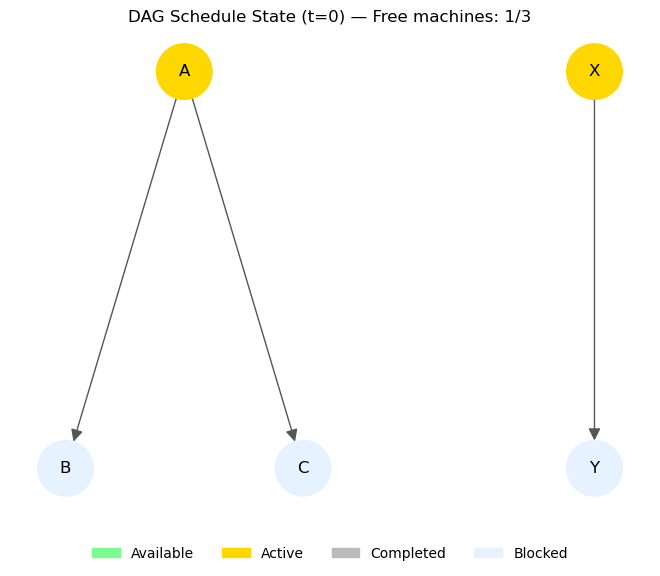


=== GREEDY STEP ===
Time step: 1
Machines: 3/3 free

DAG 0:
  Inactive : ['B', 'C']
  Active   : []
  Completed: ['A']

DAG 1:
  Inactive : ['Y']
  Active   : []
  Completed: ['X']

Available jobs: ['B', 'C', 'Y']


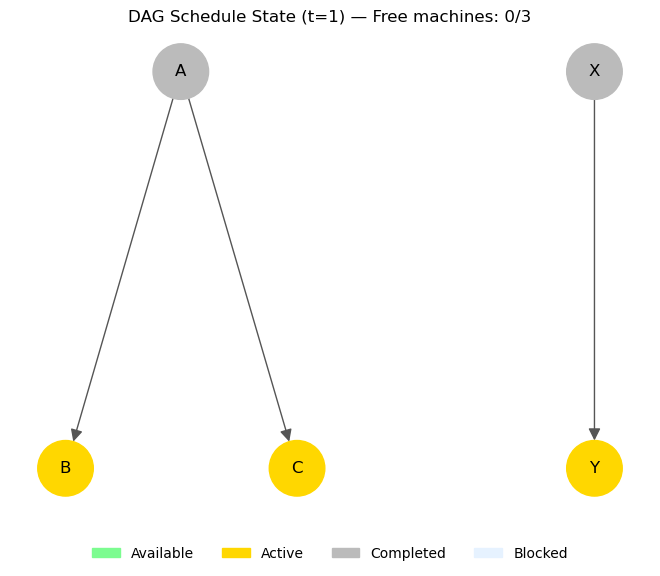


=== GREEDY STEP ===
Time step: 2
Machines: 0/3 free

DAG 0:
  Inactive : []
  Active   : ['C', 'B']
  Completed: ['A']

DAG 1:
  Inactive : []
  Active   : ['Y']
  Completed: ['X']

Available jobs: []


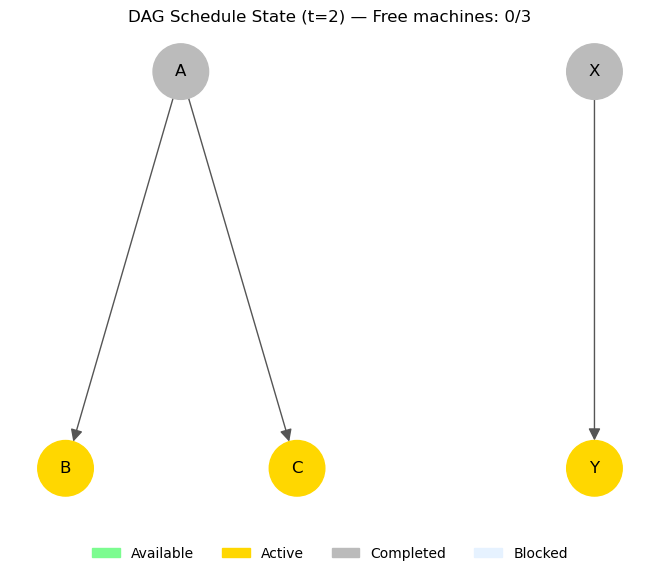


=== ALL JOBS COMPLETED ===


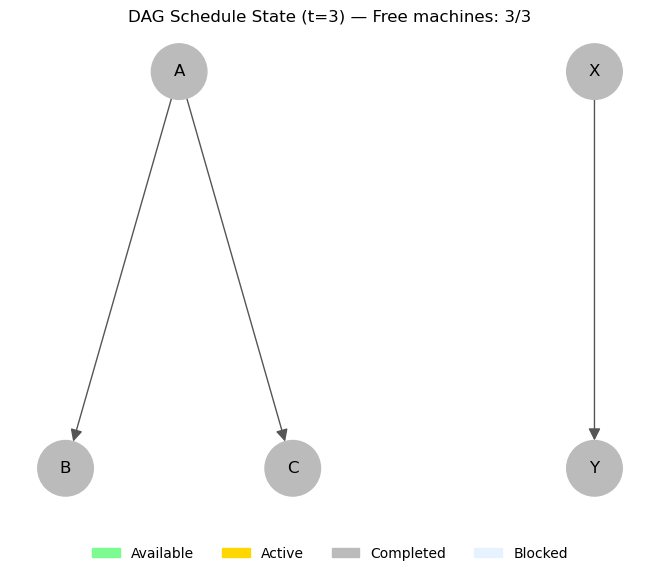

In [ ]:
from job import Job
from dag import DAG
from dag_schedule import DAGSchedule

def dump_schedule_state(sched, header=None):
    if header:
        print(f"\n=== {header} ===")

    print(f"Time step: {sched.time_step}")
    print(f"Machines: {sched.free_machines}/{sched.num_machines} free")

    for i, dag in enumerate(sched.dags):
        print(f"\nDAG {i}:")
        print("  Inactive :", [j.name for j in sched.inactive[dag]])
        print("  Active   :", [j.name for j in sched.active[dag]])
        print("  Completed:", [j.name for j in sched.completed[dag]])

    avail = [job.name for _, job in sched.available()]
    print("\nAvailable jobs:", avail)


def greedy_schedule(sched):
    """
    Time-driven greedy scheduler.
    Always advances time.
    Never raises deadlock.
    """
    total_jobs = sum(len(dag.nodes()) for dag in sched.dags)

    while True:
        completed_jobs = sum(len(sched.completed[dag]) for dag in sched.dags)
        if completed_jobs == total_jobs:
            print("\n=== ALL JOBS COMPLETED ===")
            sched.draw()
            break

        dump_schedule_state(sched, "GREEDY STEP")

        # Try to start jobs
        for dag, job in list(sched.available()):
            if sched.free_machines <= 0:
                break
            sched.consume(dag, job)

        sched.draw()

        # ALWAYS advance time
        sched.step()

# ---------------- Define DAG jobs ----------------

A = Job("A", time_estimate=1)
B = Job("B", time_estimate=2)
C = Job("C", time_estimate=2)

X = Job("X", time_estimate=1)
Y = Job("Y", time_estimate=2)

dag1 = DAG()
dag1.add_edge(A, B)
dag1.add_edge(A, C)

dag2 = DAG()
dag2.add_edge(X, Y)


# ---------------- Initialize schedule (TWO MACHINES) ----------------
sched = DAGSchedule([dag1, dag2], num_machines=3)
greedy_schedule(sched)